# ChangeStar workflow

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
A practical, end-to-end workflow using the ChangeStar model
</div>
<!-- markdownlint-enable MD033 -->

---

You now understand the siamese-network idea conceptually. This page runs a specific, pretrained implementation of it, ChangeStar, on very high-resolution {term}`VEXCEL` aerial imagery of a residential district in northern Osaka, Japan. Between 2022 and 2025, a new housing estate was built there on previously cleared and levelled ground. The next two pages then dig into ChangeStar's output, its thresholds and its export options, using the same image pair.

---

## 1. Motivation

This is the page where the previous page's architecture concepts become an actual working detector. ChangeStar is also a good illustration of a broader pattern: rather than training a change detection model from scratch, you use one that arrives already pretrained to generalize across regions, similar in spirit to the pretrained segmentation models from L07. You need no labels of your own, only two images of the same place. The price is that you must check carefully whether your images match what the model expects, and whether the model was trained for the kind of change you care about.

---

## 2. Core idea

**{term}`ChangeStar`** (Zheng et al., 2021) jointly performs change detection and {term}`semantic segmentation <Semantic Segmentation>`. Instead of only producing a binary change mask, it also outputs a building segmentation for each of the two input dates. Both dates pass through the same encoder, as in the siamese networks from the previous page; a small extra module (called *ChangeMixin*) then compares the two feature maps to predict change. Knowing what exists at each time step helps the model decide what has changed between them.

The weights used here come from **{term}`Changen2`** (Zheng et al., 2024), a generative model that *simulates* change: it produces large numbers of synthetic, perfectly labeled image pairs ("this building appeared here"). Pretraining on millions of such synthetic pairs is what lets ChangeStar work on new regions without any local labels, a {term}`zero-shot <Zero-Shot Segmentation>` use of the model. The model therefore knows "building change" well, because that is what most of its training data showed, but it has never seen your study area.

---

## 3. Workflow

### A. Set up

In [1]:
# If required in a new environment, run once and restart the kernel:
# %pip install -U "geoai-py[extra]"

import logging
import os
import time
import warnings
from pathlib import Path

# Hide routine status messages from the libraries used below
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
for name in ["httpx", "huggingface_hub", "pyogrio", "numexpr", "rasterio"]:
    logging.getLogger(name).setLevel(logging.ERROR)

import geoai
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from geoai.change_detection import ChangeStarDetection, list_changestar_models

DATA_DIR = Path("data/raw")
RGB_DIR = Path("data/processed")
OUT_DIR = Path("changestar_results")
for folder in [DATA_DIR, RGB_DIR, OUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

device = geoai.get_device()
print(f"Using device: {device}")

Using device: mps


`get_device()` checks which accelerator is available: `cuda` for an NVIDIA {term}`GPU`, `mps` for Apple silicon, otherwise `cpu`. Note the result; you will pass it to the model explicitly in step F.

### B. Download the image pair

In [2]:
BASE_URL = "https://data.source.coop/giuz/sds320/L10/data/"
raw_paths = {}
for year in [2022, 2025]:
    filename = f"vexcel_osaka_change_{year}.tif"
    raw_paths[year] = DATA_DIR / filename
    if not raw_paths[year].exists():
        geoai.download_file(BASE_URL + filename, output_path=str(raw_paths[year]))
    print(f"{year}: {raw_paths[year]}")

2022: data/raw/vexcel_osaka_change_2022.tif
2025: data/raw/vexcel_osaka_change_2025.tif


### C. Inspect the metadata

In [3]:
for year, path in raw_paths.items():
    with rasterio.open(path) as src:
        width_m = src.width * src.res[0]
        height_m = src.height * src.res[1]
        print(f"{year}: {src.count} bands {src.descriptions}, dtype {src.dtypes[0]}")
        print(f"      {src.width} x {src.height} px at {src.res[0]} m = {width_m:.0f} x {height_m:.0f} m, {src.crs}")
        print(f"      collection: {src.tags().get('COLLECTION')}")

2022: 4 bands ('blue', 'green', 'red', 'nir'), dtype uint8
      3000 x 1500 px at 0.2 m = 600 x 300 m, EPSG:6674
      collection: jp-28-toyonaka-2022
2025: 4 bands ('blue', 'green', 'red', 'nir'), dtype uint8
      3000 x 1500 px at 0.2 m = 600 x 300 m, EPSG:6674
      collection: jp-27-toyonaka-2025


Both images cover the same 600 × 300 m area on the same 20 cm grid, so they are directly comparable pixel by pixel. Two details matter for what follows. First, at 20 cm a single house covers thousands of pixels, roughly 50 times finer than the 10 m Sentinel-2 pixels on page 3: this imagery is suited to *object-level* change such as individual buildings. Second, the bands are stored as **blue, green, red, NIR**, the same {term}`band order <Band Order>` you met with VEXCEL imagery in L07.

### D. Look at the pair

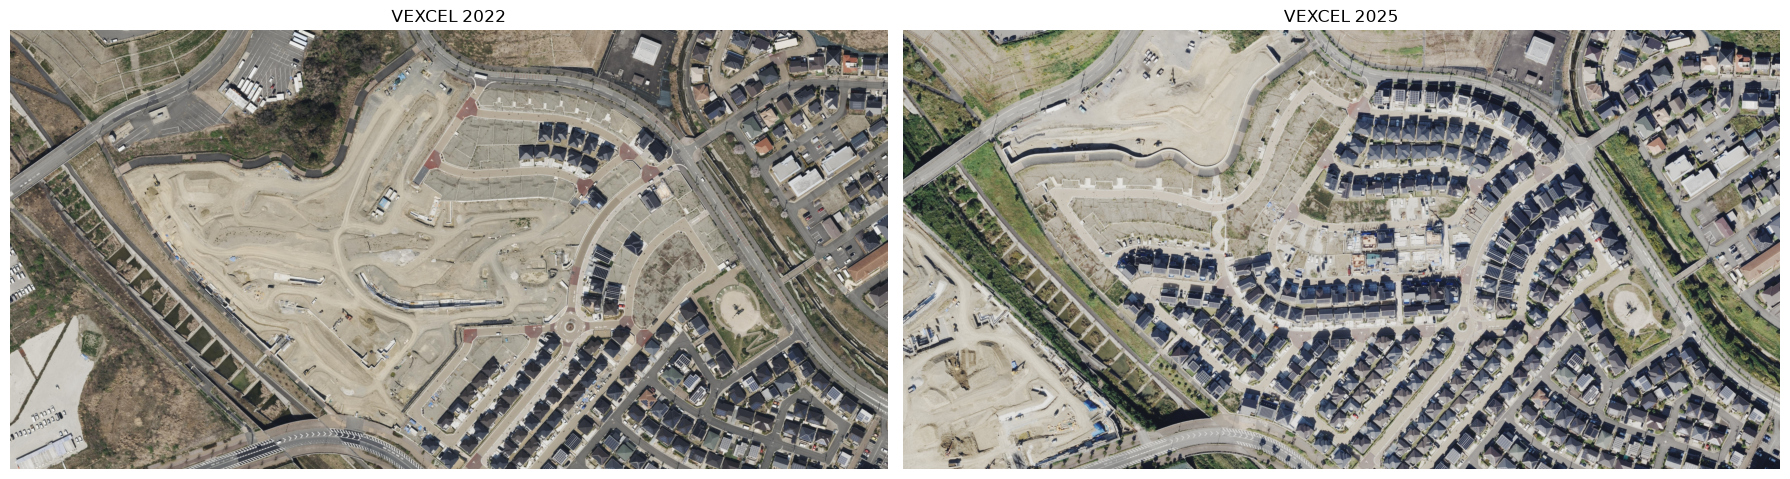

In [4]:
def read_rgb(path):
    """Read a VEXCEL image (blue, green, red, NIR) as an RGB array for display."""
    with rasterio.open(path) as src:
        return np.dstack([src.read(3), src.read(2), src.read(1)])  # red, green, blue

rgb = {year: read_rgb(path) for year, path in raw_paths.items()}

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, year in zip(axes, rgb):
    ax.imshow(rgb[year])
    ax.set_title(f"VEXCEL {year}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In 2022, the centre and left of the scene are a construction site: graded terraces, new access roads and only a few finished houses. By 2025, rows of detached houses fill the central terraces, while the terraces in the upper left are still unbuilt. The established neighbourhood along the right and bottom edges is largely unchanged. Look for other differences too: in the bottom-left corner, a large white building has disappeared, and the vehicles on the car park in the upper left have moved. Colours and shadows look broadly similar in both images, so the obvious comparability problems from page 2 do not apply here, but shadows and the lean of tall objects depend on the flight geometry and can differ slightly between acquisitions.

For a closer look, an interactive {term}`split-panel map <Split-Panel Map>` lets you slide between the two dates. It appears when you run this page yourself:

In [5]:
geoai.create_split_map(
    left_layer=str(raw_paths[2022]),
    right_layer=str(raw_paths[2025]),
    left_label="VEXCEL 2022",
    right_label="VEXCEL 2025",
    left_args={"indexes": [3, 2, 1]},
    right_args={"indexes": [3, 2, 1]},
)

### E. Match the band order the model expects

ChangeStar was trained on RGB images. `geoai`'s ChangeStar wrapper simply takes the **first three bands** of each file and treats them as red, green and blue. For our files, those are blue, green and red, so without a correction the model would see every image with red and blue swapped. We therefore write RGB copies of both images before running the model.

In [6]:
rgb_paths = {}
for year, path in raw_paths.items():
    rgb_paths[year] = RGB_DIR / f"vexcel_osaka_{year}_rgb.tif"
    with rasterio.open(path) as src:
        profile = src.profile
        profile.update(count=3)
        with rasterio.open(rgb_paths[year], "w", **profile) as dst:
            dst.write(src.read([3, 2, 1]))       # red, green, blue
            dst.descriptions = ("red", "green", "blue")
    print(f"{year}: {rgb_paths[year]}")

2022: data/processed/vexcel_osaka_2022_rgb.tif


2025: data/processed/vexcel_osaka_2025_rgb.tif


`src.read([3, 2, 1])` uses Rasterio's 1-based band numbers to read red, green and blue in that order. The {term}`metadata <Metadata>` (`profile`) is copied from the original file, so the copy keeps the same grid, {term}`CRS <Coordinate Reference System>` and data type; only the band count changes from four to three.

```{admonition} A silent error
:class: warning
Feeding the original blue-green-red-NIR files to ChangeStar does not raise any error. The model simply receives images with the wrong colours and returns a result anyway. On this pair, the outcome even looks plausible at first sight, with a slightly different changed area. Errors like this are only caught by checking the band order in the metadata *before* running a model, as in step C.
```

### F. Choose and load a model variant

In [7]:
for short_name, full_name in list_changestar_models().items():
    print(f"{short_name:22s} -> {full_name}")

s0_s1c1_vitb           -> s0_init_s1c1_changestar_vitb_1x256
s0_s1c5_vitb           -> s0_init_s1c5_changestar_vitb_1x256
s0_s9c1_vitb           -> s0_init_s9c1_changestar_vitb_1x256
s0_xview2_s1c5_vitb    -> s0_init_xView2_ft_s1c5_changestar_vitb_1x256
s1_s1c1_vitb           -> s1_init_s1c1_changestar_vitb_1x256
s1_s1c1_vitl           -> s1_init_s1c1_changestar_vitl_1x256
s9_s9c1_vitb           -> s9_init_s9c1_changestar_vitb_1x256


The short names follow a fixed pattern, `<pretraining data>_<modeling type>_<backbone>`:

| Part | Values | Meaning |
| --- | --- | --- |
| Pretraining data | `s0`, `s1`, `s9` | Which synthetic Changen2 dataset the weights were pretrained on: `s1` is a building change dataset, `s9` a land-cover change dataset with 9 classes, `s0` a much larger, class-agnostic one |
| Modeling type | `s1c1`, `s9c1`, `s1c5` | What the model outputs: the number of **s**emantic classes per date, and the number of **c**hange classes. `s1c1` = one semantic class (building) and binary change; `s9c1` = nine land-cover classes and binary change; `s1c5` = building plus five change (damage) classes |
| Backbone | `vitb`, `vitl` | {term}`Vision Transformer` Base or Large encoder |
| `xview2` | (optional) | Additionally {term}`fine-tuned <Fine-Tuning>` on the xView2 building damage dataset |

For building change, `s1_s1c1_vitb` is the natural starting point: pretrained on building change, outputs one building class per date plus a binary change map, with a mid-sized backbone.

In [8]:
detector = ChangeStarDetection(model_name="s1_s1c1_vitb", device=device)

2026-11-15 21:23:48, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s1c1_cstar_vitb_1x256.pth


2026-11-15 21:23:48, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s1c1 | pre-trained data: Changen2-S1-15k | finetuned on: None


The weights download automatically the first time you use a variant, and the log line printed while loading confirms what you got: the modeling type (`s1c1`) and the pretraining data (`Changen2-S1-15k`), the same parts as in the short name. We pass `device=device` explicitly: if you leave it out, the wrapper falls back to the CPU even when a GPU is available.

### G. Run change detection

In [9]:
start = time.time()
result = detector.predict(
    str(rgb_paths[2022]),
    str(rgb_paths[2025]),
    output_change=str(OUT_DIR / "change_map.tif"),
    output_t1_semantic=str(OUT_DIR / "t1_buildings.tif"),
    output_t2_semantic=str(OUT_DIR / "t2_buildings.tif"),
    output_vector=str(OUT_DIR / "changes.gpkg"),
)
print(f"Prediction took {time.time() - start:.0f} s on {device}")

Prediction took 16 s on mps


`predict()` takes the earlier (T1) and the later (T2) image and returns a dictionary of results, which the next page explores in detail. Its main arguments:

| Argument | Default | Explanation |
| --- | --- | --- |
| `image1_path`, `image2_path` | | The earlier (T1) and later (T2) image. Their order matters: swapping them turns "new building" into "demolished building". |
| `output_change` | `None` | Saves the binary change map as a GeoTIFF. |
| `output_t1_semantic`, `output_t2_semantic` | `None` | Save the building masks for each date as GeoTIFFs. |
| `output_vector` | `None` | Converts the change map to polygons and saves them, here as a {term}`GeoPackage`. |
| `tile_size` | `1024` | Large images are processed in tiles of this size (in pixels) and stitched back together: {term}`tiled inference <Tiled Inference>`, as in earlier lessons. |
| `overlap` | `64` | Neighbouring tiles overlap by this many pixels; predictions in the overlap are averaged to avoid visible seams. |
| `threshold` | `0.5` | Probability above which a pixel counts as changed (and as building). Page 7 explores this choice. |

Without the `output_*` paths, results exist only in memory as `result`, and nothing is saved for GIS use.

### H. A first summary

Changed area:            10,799 m² (6.0% of the scene)
Building area in 2022:   17,524 m²
Building area in 2025:   28,398 m²


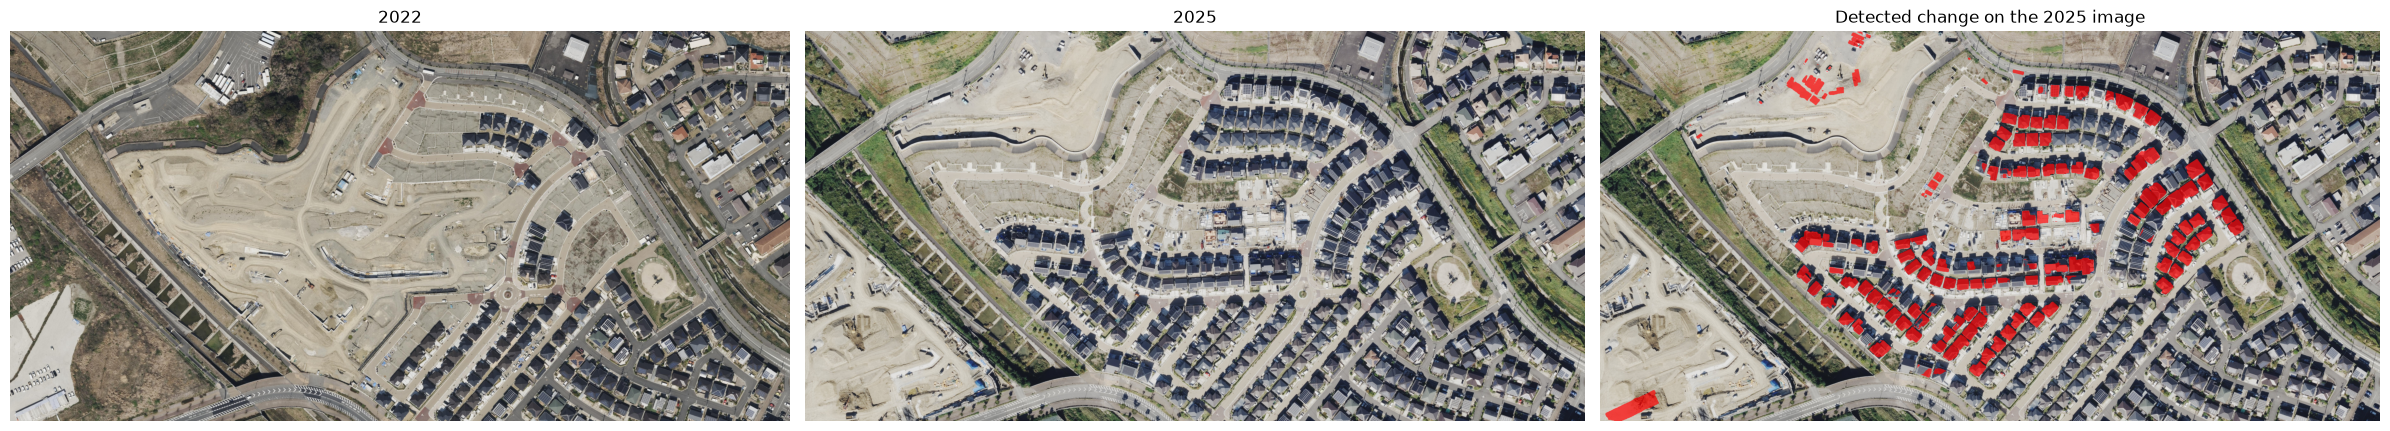

In [10]:
PIXEL_AREA_M2 = 0.2 * 0.2  # one 20 cm pixel

changed_m2 = result["change_map"].sum() * PIXEL_AREA_M2
buildings_2022_m2 = result["t1_semantic"].sum() * PIXEL_AREA_M2
buildings_2025_m2 = result["t2_semantic"].sum() * PIXEL_AREA_M2

print(f"Changed area:          {changed_m2:8,.0f} m² ({100 * result['change_map'].mean():.1f}% of the scene)")
print(f"Building area in 2022: {buildings_2022_m2:8,.0f} m²")
print(f"Building area in 2025: {buildings_2025_m2:8,.0f} m²")

fig, axes = plt.subplots(1, 3, figsize=(24, 4.5))
axes[0].imshow(rgb[2022])
axes[0].set_title("2022")
axes[1].imshow(rgb[2025])
axes[1].set_title("2025")
axes[2].imshow(rgb[2025])
axes[2].imshow(np.ma.masked_equal(result["change_map"], 0), cmap="autumn", alpha=0.7)
axes[2].set_title("Detected change on the 2025 image")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The detected change concentrates on the new houses on the central terraces, while the established neighbourhood stays largely unflagged. A few flags appear elsewhere: the demolished building in the bottom-left corner (a real change, but a *loss* rather than a gain), and small spots on the car park in the upper left. The building area per date gives a first plausibility check: it grows by about 11,000 m², roughly the footprint of the new houses. Whether every new house was found, and whether every flagged area is real, is what the next page examines.

Running the model again on every page would waste time, so we save the full result for pages 6 and 7:

In [11]:
arrays = {key: value for key, value in result.items() if isinstance(value, np.ndarray)}
np.savez_compressed(OUT_DIR / "changestar_s1_result.npz", **arrays)
print("Saved:", sorted(arrays))

Saved: ['change_map', 'change_prob', 't1_semantic', 't1_semantic_prob', 't2_semantic', 't2_semantic_prob']


---

## 4. Python reactivation

- `list_changestar_models().items()` iterates over a dictionary's key-value pairs together, here short and full model names.
- `Path(...).mkdir(parents=True, exist_ok=True)` creates a folder, including missing parent folders, and does nothing if it already exists.
- `src.profile` is a dictionary of raster metadata; `profile.update(count=3)` changes one entry before the profile is reused to create a new file.
- `np.ma.masked_equal(array, 0)` hides all zero values, so only the changed pixels are drawn on top of the image.
- `np.savez_compressed(path, **arrays)` saves several NumPy arrays in one compressed file; `**arrays` unpacks the dictionary into named arguments, so each array is stored under its key.

---

## 5. Common pitfalls

- **Not checking the band order.** VEXCEL imagery is stored as blue, green, red, NIR; a model that expects RGB silently receives swapped colours (step E).
- **Skipping the visual inspection in step D.** Looking at both dates is the fastest way to catch coverage, alignment or acquisition problems before a full prediction run.
- **Choosing a model variant without understanding what the name encodes.** The pretraining data and modeling type decide what the model can detect; `s9c1` maps land cover, not buildings (page 7 compares both).
- **Swapping T1 and T2.** The first image must be the earlier one; otherwise new buildings are reported as demolished ones.
- **Forgetting to specify `output_*` paths.** Without them, nothing is saved to disk for later use or GIS export.
- **Assuming a GPU is required.** A CPU run is slower (a few minutes for this scene instead of seconds) but works for a lesson-scale example.

---

## 6. Mini task

Before running step G, predict which of ChangeStar's outputs (the change map, and the building masks for 2022 and 2025) will differ most between the established neighbourhood along the right and bottom edges and the new housing estate in the centre, and why. Then check your prediction against the figure in step H.

:::{dropdown} Sample solution
:class: note

The change map should show the clearest difference: it is designed to highlight change, so it should be bright over the new houses in the centre and nearly empty over the established neighbourhood. The two building masks individually look similar in the established neighbourhood, where the same houses exist at both dates. The meaningful difference is the *new* buildings present in the 2025 mask but absent from the 2022 mask, which is exactly the comparison the change map is built to surface directly. Small flagged spots in the established neighbourhood are worth a closer look on the next page: they may be real changes (an extension, a new roof) or artefacts such as shadows and parked vehicles.
:::

---

## 7. Key takeaways

- ChangeStar jointly produces a change map and a building segmentation per date; its Changen2 weights were pretrained on synthetic change pairs, which lets it run without local labels.
- Variant names encode the pretraining data, the modeling type (semantic and change classes) and the backbone; `s1_s1c1_vitb` is the natural choice for building change.
- Check the band order before running a pretrained model: VEXCEL's blue-green-red-NIR files must be converted to RGB first, or the model silently receives wrong colours.
- Visually inspecting the image pair before prediction catches coverage and alignment problems early.
- Specifying `output_*` paths in `predict()` saves georeferenced results directly to disk, and saving the full result avoids re-running the model on later pages.

### Further reading

- OpenGeoAI, ["ChangeStar"](https://opengeoai.org/examples/changestar/) — the runnable example notebook this workflow is based on.
- OpenGeoAI, [Change Detection module documentation](https://opengeoai.org/change_detection/) — reference documentation for the `geoai.change_detection` module.
- Zheng, Ma, Zhang and Zhong (2021), ["Change is Everywhere: Single-Temporal Supervised Object Change Detection in Remote Sensing Imagery"](https://arxiv.org/abs/2108.07002), ICCV — the paper introducing ChangeStar.
- Zheng, Ermon, Kim, Zhang and Zhong (2024), ["Changen2: Multi-Temporal Remote Sensing Generative Change Foundation Model"](https://arxiv.org/abs/2406.17998) — the generative pretraining behind the weights used here.